# Contextual Bandits and Moderation Simulation

Portfolio packaging for Behrad Mazaheri. Original course/template credits below are retained; individual contributions are unverified.

**Static review only; no cells executed.** Historical outputs are preserved, not independently reproduced. Read README and REVIEW before citing results. Source cell indices in documentation are zero-based before this banner.

Text examples are real, but action rewards, logged propensities and cost profiles are simulated. Severity is a proxy derived from binary labels. NeuralUCB-style uses LinUCB on frozen learned features. OPE uses the same log for fitting and estimation without cross-fitting; it is not unbiased evidence for a deployed policy. Safety masks are experimental heuristics, not a production safety guarantee.


# Textual Contextual Bandits with Moderation Data


---

## Problem setting

You are supposed to design a moderation decision policy for user-generated text. For each post, the system must choose one action:

| Action id | Action | Operational meaning |
|---:|---|---|
| 0 | `allow` | publish immediately |
| 1 | `review` | route to human moderation |
| 2 | `block` | automatically remove |

You only observe the reward of the action you chose. This is contextual bandit feedback, not supervised full-information learning.

---
## Important note on running

This notebook requires internet access the first time it downloads the Hugging Face datasets. After caching, it can be rerun offline on the same machine.

Install dependencies:

```bash
pip install numpy pandas matplotlib torch datasets tqdm
```

In [4]:
import math
import re
import hashlib
import random
import warnings
from dataclasses import dataclass
from typing import Callable, Dict, Iterable, List, Optional, Tuple
from pathlib import Path
import urllib.request
import time

import numpy as np
import pandas as pd
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
import matplotlib.pyplot as plt

# 1. local CSV cache,
# 2. official TweetEval GitHub raw files,
# 3. Hugging Face datasets,
# 4. original-repo prepared memmaps if available.
try:
    from datasets import load_dataset
except Exception:
    load_dataset = None

SEED = 17
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

ACTIONS = ["allow", "review", "block"]
ALLOW, REVIEW, BLOCK = 0, 1, 2
N_ACTIONS = len(ACTIONS)

def set_seed(seed: int = SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

set_seed(SEED)
warnings.filterwarnings("ignore", category=UserWarning)

Device: cuda


In [5]:
@dataclass
class Config:
    base_dataset_name: str = "cardiffnlp/tweet_eval"
    base_dataset_config: str = "offensive"

    ood_dataset_name: str = "cardiffnlp/tweet_eval"
    ood_dataset_config: str = "hate"

    # Keep these modest for CPU labs. Increase for stronger results.
    n_logged: int = 6000
    n_eval: int = 2000
    n_ood: int = 2000

    # Hashing vectorizer
    hash_dim: int = 256
    min_token_len: int = 2

    # Neural reward model
    hidden: int = 128
    dropout_p: float = 0.15
    batch_size: int = 256
    reward_epochs: int = 5
    ensemble_epochs: int = 3
    risk_epochs: int = 5
    lr: float = 1e-3
    weight_decay: float = 1e-4

    # Logging policy
    behavior_temperature: float = 0.75
    behavior_uniform_mix: float = 0.10

    # Policies
    epsilon: float = 0.10
    ensemble_size: int = 3
    mc_samples: int = 10

    # Safe exploration
    unsafe_threshold: float = 0.55
    extreme_unsafe_threshold: float = 0.80
    safety_margin: float = 0.05

    # LinUCB and NeuralUCB
    linucb_alpha: float = 0.60
    linucb_l2: float = 1.00
    neuralucb_alpha: float = 0.75
    neural_feature_dim: int = 128

cfg = Config()
cfg


Config(base_dataset_name='cardiffnlp/tweet_eval', base_dataset_config='offensive', ood_dataset_name='cardiffnlp/tweet_eval', ood_dataset_config='hate', n_logged=6000, n_eval=2000, n_ood=2000, hash_dim=256, min_token_len=2, hidden=128, dropout_p=0.15, batch_size=256, reward_epochs=5, ensemble_epochs=3, risk_epochs=5, lr=0.001, weight_decay=0.0001, behavior_temperature=0.75, behavior_uniform_mix=0.1, epsilon=0.1, ensemble_size=3, mc_samples=10, unsafe_threshold=0.55, extreme_unsafe_threshold=0.8, safety_margin=0.05, linucb_alpha=0.6, linucb_l2=1.0, neuralucb_alpha=0.75, neural_feature_dim=128)

## 1. Real dataset loading
### Task 1

Run the loader and inspect examples.

In [6]:
CACHE_DIR = Path("./tweeteval_cache")
CACHE_DIR.mkdir(exist_ok=True)

TWEETEVAL_GITHUB_BASE = "https://raw.githubusercontent.com/cardiffnlp/tweeteval/main/datasets"

# GitHub uses val, while Hugging Face commonly calls this validation.
SPLIT_TO_GITHUB = {
    "train": "train",
    "validation": "val",
    "val": "val",
    "test": "test",
}

def _sample_or_all(df: pd.DataFrame, n: int, seed: int) -> pd.DataFrame:
    if len(df) <= n:
        return df.sample(frac=1.0, random_state=seed).reset_index(drop=True)
    return df.sample(n=n, random_state=seed).reset_index(drop=True)

def _read_cached_csv(task: str, split: str) -> Optional[pd.DataFrame]:
    path = CACHE_DIR / f"tweeteval_{task}_{split}.csv"
    if path.exists():
        df = pd.read_csv(path)
        if {"text", "label"}.issubset(df.columns):
            df["label"] = df["label"].astype(int)
            df["source"] = f"local_cache/{path.name}"
            return df
    return None

def _write_cached_csv(df: pd.DataFrame, task: str, split: str) -> None:
    path = CACHE_DIR / f"tweeteval_{task}_{split}.csv"
    df[["text", "label", "source"]].to_csv(path, index=False)

def _download_text(url: str, timeout: int = 30, retries: int = 4) -> str:
    last_error = None
    for attempt in range(retries):
        try:
            req = urllib.request.Request(
                url,
                headers={
                    "User-Agent": "Mozilla/5.0 educational-notebook",
                    "Accept": "text/plain,*/*",
                },
            )
            with urllib.request.urlopen(req, timeout=timeout) as response:
                return response.read().decode("utf-8", errors="replace")
        except Exception as e:
            last_error = e
            sleep_s = min(2 ** attempt, 8)
            print(f"Download failed attempt {attempt+1}/{retries}: {url}\n  {type(e).__name__}: {e}\n  retrying in {sleep_s}s")
            time.sleep(sleep_s)
    raise RuntimeError(f"Could not download {url}: {last_error}")

def load_tweeteval_from_github(task: str, split: str) -> pd.DataFrame:
    """Load official TweetEval text/label files directly from GitHub raw.
    Labels are stored as a single whitespace-separated line in the official repo.
    Text files contain one tweet per line.
    """
    cached = _read_cached_csv(task, split)
    if cached is not None:
        return cached

    gh_split = SPLIT_TO_GITHUB[split]
    text_url = f"{TWEETEVAL_GITHUB_BASE}/{task}/{gh_split}_text.txt"
    label_url = f"{TWEETEVAL_GITHUB_BASE}/{task}/{gh_split}_labels.txt"

    print(f"Downloading TweetEval {task}/{split} from official GitHub raw files.")
    text_raw = _download_text(text_url)
    label_raw = _download_text(label_url)

    texts = [line.strip() for line in text_raw.splitlines()]
    labels = [int(x) for x in label_raw.split()]

    if len(texts) != len(labels):
        raise ValueError(
            f"Text/label length mismatch for {task}/{split}: "
            f"{len(texts)} texts vs {len(labels)} labels"
        )

    df = pd.DataFrame({"text": texts, "label": labels})
    df["label"] = df["label"].astype(int)
    df["source"] = f"github_raw/tweeteval/{task}/{split}"
    _write_cached_csv(df, task, split)
    return df

def load_tweeteval_from_hf(dataset_name: str, config_name: str, split: str) -> pd.DataFrame:
    if load_dataset is None:
        raise RuntimeError("datasets is not installed; skipping Hugging Face fallback.")
    ds = load_dataset(dataset_name, config_name, split=split)
    df = pd.DataFrame(ds)
    if "text" not in df.columns or "label" not in df.columns:
        raise ValueError(f"Expected text and label columns, got {df.columns.tolist()}")
    df = df[["text", "label"]].copy()
    df["label"] = df["label"].astype(int)
    df["source"] = f"huggingface/{dataset_name}/{config_name}/{split}"
    return df

def load_original_repo_memmap(task: str, split_hint: str = "train") -> pd.DataFrame:
    """Fallback for users who already ran the original repo's prepare_data.py.

    The original repo stores GPT-2 token ids and labels in hf_data/tweet_eval/{task}.
    This fallback creates pseudo-text from token ids so the rest of the notebook can
    still run without Hugging Face/GitHub. Prefer GitHub/HF because they preserve text.
    """
    possible_roots = [
        Path("hf_data") / "tweet_eval" / task,
        Path("./llm-bandit-main") / "hf_data" / "tweet_eval" / task,
        Path("../llm-bandit-main") / "hf_data" / "tweet_eval" / task,
        Path("/mnt/data/llm-bandit-main") / "hf_data" / "tweet_eval" / task,
    ]
    root = next((p for p in possible_roots if (p / "data_labels.bin").exists()), None)
    if root is None:
        raise FileNotFoundError(f"No original repo memmap found for task={task}")

    block_size = 64
    labels = np.memmap(root / "data_labels.bin", dtype=np.uint16, mode="r")
    text_ids = np.memmap(root / "data_text.bin", dtype=np.uint16, mode="r").reshape(-1, block_size)

    pseudo_texts = []
    for row in text_ids:
        toks = [f"tok_{int(x)}" for x in row if int(x) != 0]
        pseudo_texts.append(" ".join(toks[:80]))

    df = pd.DataFrame({"text": pseudo_texts, "label": labels.astype(int)})
    df["source"] = f"original_repo_memmap/{root}"
    return df

def load_real_tweeteval_task(task: str, split: str, cfg: Config) -> pd.DataFrame:
    """Robust loader that avoids Hugging Face unless needed."""
    try:
        return load_tweeteval_from_github(task, split)
    except Exception as github_error:
        print(f"GitHub raw loading failed for {task}/{split}: {type(github_error).__name__}: {github_error}")

    try:
        return load_tweeteval_from_hf(cfg.base_dataset_name, task, split)
    except Exception as hf_error:
        print(f"Hugging Face fallback failed for {task}/{split}: {type(hf_error).__name__}: {hf_error}")

    try:
        return load_original_repo_memmap(task, split)
    except Exception as memmap_error:
        raise RuntimeError(
            f"All real-data loading methods failed for TweetEval {task}/{split}.\n"
            f"Fix options:\n"
            f"  1. Re-run later; Hugging Face 429 usually clears.\n"
            f"  2. Ensure GitHub raw access is available.\n"
            f"  3. Manually place CSVs in ./tweeteval_cache/ named tweeteval_{task}_{split}.csv "
            f"with columns text,label.\n"
            f"  4. Run the original repo prepare_data.py --data {task} to create hf_data memmaps.\n"
            f"Last memmap error: {type(memmap_error).__name__}: {memmap_error}"
        )

def load_real_moderation_data(cfg: Config) -> Tuple[pd.DataFrame, pd.DataFrame, pd.DataFrame]:
    """Load real in-domain and out-of-domain moderation datasets robustly."""
    # In-domain offensive data.
    train = load_real_tweeteval_task("offensive", "train", cfg)
    validation = load_real_tweeteval_task("offensive", "validation", cfg)
    test = load_real_tweeteval_task("offensive", "test", cfg)
    eval_pool = pd.concat([validation, test], ignore_index=True)

    # OOD hate data.
    ood_validation = load_real_tweeteval_task("hate", "validation", cfg)
    ood_test = load_real_tweeteval_task("hate", "test", cfg)
    ood_pool = pd.concat([ood_validation, ood_test], ignore_index=True)

    logged = _sample_or_all(train, cfg.n_logged, SEED + 1)
    eval_df = _sample_or_all(eval_pool, cfg.n_eval, SEED + 2)
    ood_df = _sample_or_all(ood_pool, cfg.n_ood, SEED + 3)

    return logged, eval_df, ood_df

logged_raw, eval_raw, ood_raw = load_real_moderation_data(cfg)

print("Loaded real datasets:")
display(pd.DataFrame({
    "split": ["logged_train", "in_domain_eval", "ood_hate_eval"],
    "rows": [len(logged_raw), len(eval_raw), len(ood_raw)],
    "harmful_rate": [logged_raw.label.mean(), eval_raw.label.mean(), ood_raw.label.mean()],
    "source": [logged_raw.source.iloc[0], eval_raw.source.iloc[0], ood_raw.source.iloc[0]],
}))

display(logged_raw.sample(min(10, len(logged_raw)), random_state=SEED))

Loaded real datasets:


,split,rows,harmful_rate,source
0,logged_train,6000,0.331167,github_raw/tweeteval/offensive/train
1,in_domain_eval,2000,0.317000,github_raw/tweeteval/offensive/validation
2,ood_hate_eval,2000,0.424000,github_raw/tweeteval/hate/validation


,text,label,source
4503,@user Antifa thugs remind me of orcs if they a...,1,github_raw/tweeteval/offensive/train
1424,13/? BOOOM. The MAC telling the @user to pay...,0,github_raw/tweeteval/offensive/train
4414,@user That’s why conservatives are so afraid o...,0,github_raw/tweeteval/offensive/train
5914,@user You can’t pretend to care about women wh...,0,github_raw/tweeteval/offensive/train
3768,@user Diversity = Success? LMAO,0,github_raw/tweeteval/offensive/train
5729,@user And when did Breitbart become a reliable...,0,github_raw/tweeteval/offensive/train
1491,. @user @user @user Fake conservatives and the...,1,github_raw/tweeteval/offensive/train
3592,@user @user Insanity...just like the commies! ...,0,github_raw/tweeteval/offensive/train
4378,@user WHAT THE FUCK,1,github_raw/tweeteval/offensive/train
318,@user Strange how Gun Control never works Crim...,0,github_raw/tweeteval/offensive/train


## 2. Text diagnostics and severity proxy

 Real moderation costs often depend on severity, but `tweet_eval/offensive` only provides binary labels.

We therefore construct a **severity proxy** from text signals and the harmful label. This is not perfect and should be discussed critically. It is used only to define richer reward and regret for the bandit environment.

In [7]:

TOKEN_RE = re.compile(r"[A-Za-z_@#!']+")

MILD_RISK_TERMS = {
    "stupid", "idiot", "shut", "hate", "trash", "dumb", "fool", "sucks",
    "worst", "clown", "garbage", "nonsense", "awful", "pathetic"
}

def tokenize(text: str) -> List[str]:
    return TOKEN_RE.findall(str(text).lower())

def text_risk_score(text: str) -> float:
    """Heuristic toxicity/risk signal in [0, 1].

    The real labels remain the ground truth. This score is only a weak proxy
    used for logging-policy bias and severity simulation.
    """
    text = str(text)
    toks = tokenize(text)
    n = max(len(toks), 1)

    risk_hits = sum(tok.strip("#!@'") in MILD_RISK_TERMS for tok in toks)
    risk_term_score = risk_hits / math.sqrt(n)

    exclaim_score = min(text.count("!") / 3.0, 1.0)
    all_alpha = [tok for tok in re.findall(r"[A-Za-z]+", text) if len(tok) >= 3]
    caps_rate = 0.0 if len(all_alpha) == 0 else np.mean([tok.isupper() for tok in all_alpha])
    hashtag_or_mention = 1.0 if ("#" in text or "@" in text) else 0.0

    raw = 0.60 * risk_term_score + 0.20 * exclaim_score + 0.25 * caps_rate + 0.05 * hashtag_or_mention
    return float(np.clip(raw, 0.0, 1.0))

def severity_proxy(text: str, label: int) -> float:
    """Map binary harmful label plus text risk into a severity score in [0, 1]."""
    r = text_risk_score(text)
    if int(label) == 1:
        # Harmful examples start at moderate severity and increase with text risk.
        return float(np.clip(0.45 + 0.55 * r, 0.0, 1.0))
    # Benign examples may still contain borderline words; keep severity low.
    return float(np.clip(0.20 * r, 0.0, 0.35))

def add_text_diagnostics(df: pd.DataFrame) -> pd.DataFrame:
    """Add simple diagnostics used by the simulated moderation bandit."""
    out = df.copy().reset_index(drop=True)
    tokens = out["text"].apply(tokenize)
    out["n_tokens"] = tokens.apply(len).astype(int)
    out["risk_score"] = out["text"].apply(text_risk_score).astype(float)
    out["severity"] = [severity_proxy(t, y) for t, y in zip(out["text"], out["label"])]
    out["has_risk_term"] = tokens.apply(lambda xs: any(x.strip("#!@'") in MILD_RISK_TERMS for x in xs))
    out["has_mention"] = out["text"].astype(str).str.contains("@", regex=False)
    out["has_hashtag"] = out["text"].astype(str).str.contains("#", regex=False)
    out["has_url"] = out["text"].astype(str).str.contains(r"http|www\.", case=False, regex=True)
    out["has_exclaim"] = out["text"].astype(str).str.contains("!", regex=False)
    return out

logged_df = add_text_diagnostics(logged_raw)
eval_df = add_text_diagnostics(eval_raw)
ood_df = add_text_diagnostics(ood_raw)

display(pd.DataFrame({
    "split": ["logged", "in_domain_eval", "ood_hate_eval"],
    "harmful_rate": [logged_df.label.mean(), eval_df.label.mean(), ood_df.label.mean()],
    "mean_risk_score": [logged_df.risk_score.mean(), eval_df.risk_score.mean(), ood_df.risk_score.mean()],
    "mean_severity": [logged_df.severity.mean(), eval_df.severity.mean(), ood_df.severity.mean()],
}))


,split,harmful_rate,mean_risk_score,mean_severity
0,logged,0.331167,0.087517,0.178474
1,in_domain_eval,0.317000,0.086598,0.170505
2,ood_hate_eval,0.424000,0.081074,0.219749


## 3. Reward, oracle, regret, and cost-sensitivity analysis

A moderation classifier predicts a label. A contextual bandit chooses an action.

This section defines three product cost profiles:

1. `balanced`: balanced platform policy.
2. `high_safety`: strict platform; allowing harmful content is extremely costly.
3. `free_expression`: blocking benign content is especially costly.

You must evaluate how the optimal action distribution changes under different cost profiles.

### Task 3

Implement:

- `expected_reward_for_action`
- `reward_table`
- `oracle_action_and_value`
- `expected_regret`
- cost-profile comparison


In [8]:

COST_PROFILES = {
    "balanced": {
        "benign_allow": 1.00,
        "benign_review": 0.30,
        "benign_block": -1.60,
        "harm_allow_base": -2.00,
        "harm_allow_severity": -2.20,
        "harm_review_base": 0.05,
        "harm_review_severity": 0.20,
        "harm_block_base": 0.75,
        "harm_block_severity": 0.55,
    },
    "high_safety": {
        "benign_allow": 0.85,
        "benign_review": 0.20,
        "benign_block": -1.10,
        "harm_allow_base": -3.20,
        "harm_allow_severity": -3.50,
        "harm_review_base": 0.20,
        "harm_review_severity": 0.30,
        "harm_block_base": 1.00,
        "harm_block_severity": 0.85,
    },
    "free_expression": {
        "benign_allow": 1.15,
        "benign_review": 0.15,
        "benign_block": -2.80,
        "harm_allow_base": -1.20,
        "harm_allow_severity": -1.40,
        "harm_review_base": 0.05,
        "harm_review_severity": 0.15,
        "harm_block_base": 0.45,
        "harm_block_severity": 0.35,
    },
}

ACTIVE_PROFILE = "balanced"

def expected_reward_for_action(label: int, severity: float, action: int, profile: str = ACTIVE_PROFILE) -> float:
    """Expected utility of a moderation action under a product cost profile."""
    p = COST_PROFILES[profile]
    label = int(label)
    severity = float(np.clip(severity, 0.0, 1.0))
    action = int(action)

    if label == 0:  # benign content
        if action == ALLOW:
            return float(p["benign_allow"])
        if action == REVIEW:
            return float(p["benign_review"])
        if action == BLOCK:
            return float(p["benign_block"])
    else:  # harmful content
        if action == ALLOW:
            return float(p["harm_allow_base"] - p["harm_allow_severity"] * severity)
        if action == REVIEW:
            return float(p["harm_review_base"] + p["harm_review_severity"] * severity)
        if action == BLOCK:
            return float(p["harm_block_base"] + p["harm_block_severity"] * severity)

    raise ValueError(f"Unknown action id: {action}")

def sample_observed_reward(
    label: int,
    severity: float,
    action: int,
    rng: np.random.Generator,
    profile: str = ACTIVE_PROFILE,
    noise_std: float = 0.08,
) -> float:
    return float(expected_reward_for_action(label, severity, action, profile) + rng.normal(0.0, noise_std))

def reward_table(df: pd.DataFrame, profile: str = ACTIVE_PROFILE) -> np.ndarray:
    """Return expected rewards with shape [n_examples, n_actions]."""
    rewards = np.zeros((len(df), N_ACTIONS), dtype=np.float32)
    for i, (label, severity) in enumerate(zip(df["label"].values, df["severity"].values)):
        for a in range(N_ACTIONS):
            rewards[i, a] = expected_reward_for_action(label, severity, a, profile)
    return rewards

def oracle_action_and_value(df: pd.DataFrame, profile: str = ACTIVE_PROFILE) -> Tuple[np.ndarray, np.ndarray]:
    rewards = reward_table(df, profile)
    actions = rewards.argmax(axis=1).astype(int)
    values = rewards[np.arange(len(df)), actions]
    return actions, values

def expected_regret(df: pd.DataFrame, actions: np.ndarray, profile: str = ACTIVE_PROFILE) -> np.ndarray:
    actions = np.asarray(actions, dtype=int)
    rewards = reward_table(df, profile)
    oracle_values = rewards.max(axis=1)
    chosen_values = rewards[np.arange(len(df)), actions]
    return oracle_values - chosen_values

def summarize_oracle_by_profile(df: pd.DataFrame, split_name: str) -> pd.DataFrame:
    rows = []
    for profile in COST_PROFILES:
        acts, vals = oracle_action_and_value(df, profile)
        rows.append({
            "split": split_name,
            "profile": profile,
            "oracle_value": float(np.mean(vals)),
            "allow_rate": float(np.mean(acts == ALLOW)),
            "review_rate": float(np.mean(acts == REVIEW)),
            "block_rate": float(np.mean(acts == BLOCK)),
        })
    return pd.DataFrame(rows)

oracle_profile_table = pd.concat([
    summarize_oracle_by_profile(logged_df, "logged"),
    summarize_oracle_by_profile(eval_df, "eval"),
    summarize_oracle_by_profile(ood_df, "ood_hate"),
], ignore_index=True)

display(oracle_profile_table)


,split,profile,oracle_value,allow_rate,review_rate,block_rate
0,logged,balanced,1.009497,0.668833,0.0,0.331167
1,logged,high_safety,1.042302,0.668833,0.0,0.331167
2,logged,free_expression,0.976912,0.668833,0.0,0.331167
3,eval,balanced,1.008313,0.683000,0.0,0.317000
4,eval,high_safety,1.032875,0.683000,0.0,0.317000
5,eval,free_expression,0.983822,0.683000,0.0,0.317000
6,ood_hate,balanced,1.009946,0.576000,0.0,0.424000
7,ood_hate,high_safety,1.092790,0.576000,0.0,0.424000
8,ood_hate,free_expression,0.926984,0.576000,0.0,0.424000


## 4. Logged bandit data with propensities

We simulate a behavior policy that resembles a legacy moderation system. It uses text heuristics and randomization.

For each example it logs:

```text
x_i, a_i, r_i, p_i
```

where `p_i = behavior_policy(a_i | x_i)`.

### Task 4

Implement the behavior policy and generate logged bandit data.

In [9]:

def softmax(z: np.ndarray, temperature: float = 1.0) -> np.ndarray:
    z = np.asarray(z, dtype=np.float64)
    temperature = max(float(temperature), 1e-8)
    z = z / temperature
    z = z - np.max(z)
    exp_z = np.exp(z)
    return exp_z / np.sum(exp_z)

def behavior_action_probs(text: str, cfg: Config = cfg) -> np.ndarray:
    """Stochastic logging policy with full support.

    It is intentionally imperfect: low-risk posts are usually allowed, medium-risk
    posts are reviewed, and high-risk posts are more likely blocked.
    """
    risk = text_risk_score(text)
    prefs = np.array([
        1.25 - 3.20 * risk,              # allow decreases with risk
        0.20 - 2.00 * abs(risk - 0.50),  # review peaks near moderate risk
        -0.70 + 3.10 * risk,             # block increases with risk
    ], dtype=np.float64)
    probs = softmax(prefs, temperature=cfg.behavior_temperature)
    mix = float(np.clip(cfg.behavior_uniform_mix, 0.0, 1.0))
    probs = (1.0 - mix) * probs + mix / N_ACTIONS
    probs = probs / probs.sum()
    return probs.astype(np.float64)

def make_logged_bandit_data(df: pd.DataFrame, cfg: Config, seed: int = SEED) -> pd.DataFrame:
    rng = np.random.default_rng(seed)
    out = df.copy().reset_index(drop=True)
    actions, propensities, rewards = [], [], []

    for row in out.itertuples(index=False):
        probs = behavior_action_probs(row.text, cfg)
        a = int(rng.choice(N_ACTIONS, p=probs))
        r = sample_observed_reward(row.label, row.severity, a, rng, ACTIVE_PROFILE)
        actions.append(a)
        propensities.append(float(probs[a]))
        rewards.append(float(r))

    out["logged_action"] = np.asarray(actions, dtype=int)
    out["logged_action_name"] = [ACTIONS[a] for a in actions]
    out["propensity"] = np.asarray(propensities, dtype=float)
    out["reward"] = np.asarray(rewards, dtype=float)
    out["expected_logged_reward"] = reward_table(out)[np.arange(len(out)), out["logged_action"].values]
    out["oracle_action"], out["oracle_value"] = oracle_action_and_value(out)
    out["logged_regret"] = out["oracle_value"].values - out["expected_logged_reward"].values
    return out

bandit_log = make_logged_bandit_data(logged_df, cfg, seed=SEED + 10)

display(bandit_log.head())
display(bandit_log["logged_action_name"].value_counts(normalize=True).rename("rate").to_frame())
display(bandit_log["propensity"].describe().to_frame())


,text,label,source,n_tokens,risk_score,severity,has_risk_term,has_mention,has_hashtag,has_url,has_exclaim,logged_action,logged_action_name,propensity,reward,expected_logged_reward,oracle_action,oracle_value,logged_regret
0,"@user So funny, this was labeled as sensitive ...",1,github_raw/tweeteval/offensive/train,20,0.183333,0.550833,False,True,False,False,True,1,review,0.165479,0.222319,0.160167,2,1.052958,0.892792
1,@user @user ...I happen to know of your waywar...,0,github_raw/tweeteval/offensive/train,48,0.050000,0.010000,False,True,False,False,False,0,allow,0.780235,0.913426,1.000000,0,1.000000,0.000000
2,@user @user He/she deserves those tattoos. Hop...,0,github_raw/tweeteval/offensive/train,11,0.050000,0.010000,False,True,False,False,False,2,block,0.117764,-1.613453,-1.600000,0,1.000000,2.600000
3,@user But gun control,0,github_raw/tweeteval/offensive/train,4,0.050000,0.010000,False,True,False,False,False,0,allow,0.780235,1.089645,1.000000,0,1.000000,0.000000
4,@user He is hurt and no one has checked on him!!!,1,github_raw/tweeteval/offensive/train,11,0.250000,0.587500,False,True,False,False,True,0,allow,0.489166,-0.809872,-0.707500,2,1.073125,1.780625


,rate
logged_action_name,
allow,0.727667
block,0.153833
review,0.118500


,propensity
count,6000.000000
mean,0.584559
std,0.273358
min,0.084684
25%,0.294278
50%,0.769711
75%,0.780235
max,0.823309


## 5. Hashing text features
We are going to use a deteministic hashing vectorizer, which is weaker than larger models like GPT, yet is still handy with real text and supports the contextual-bandit methods.

### Task 5

Implement a hashing vectorizer.


In [10]:

def stable_hash(token: str, dim: int) -> int:
    digest = hashlib.md5(token.encode("utf-8")).hexdigest()
    return int(digest, 16) % int(dim)

def stable_sign(token: str) -> int:
    digest = hashlib.sha1(token.encode("utf-8")).digest()
    return 1 if (digest[0] & 1) == 0 else -1

def hashing_vectorize(texts: Iterable[str], dim: int = cfg.hash_dim, min_token_len: int = cfg.min_token_len) -> np.ndarray:
    """Signed hashing vectorizer with unigram and bigram features."""
    texts = list(texts)
    X = np.zeros((len(texts), int(dim)), dtype=np.float32)

    for i, text in enumerate(texts):
        toks = [t.strip("#!@'") for t in tokenize(text) if len(t.strip("#!@'")) >= min_token_len]
        feats = list(toks)
        feats += [f"{a}__{b}" for a, b in zip(toks[:-1], toks[1:])]
        if not feats:
            continue
        for feat in feats:
            j = stable_hash(feat, dim)
            X[i, j] += stable_sign(feat)

    norms = np.linalg.norm(X, axis=1, keepdims=True)
    X = X / np.maximum(norms, 1e-8)
    return X.astype(np.float32)

X_log = hashing_vectorize(bandit_log.text)
X_eval = hashing_vectorize(eval_df.text)
X_ood = hashing_vectorize(ood_df.text)

print("Feature shapes:", X_log.shape, X_eval.shape, X_ood.shape)


Feature shapes: (6000, 256) (2000, 256) (2000, 256)


## 6. Neural reward model from bandit feedback

The reward model predicts one value per action:

```text
Q_theta(x) = [Q(x, allow), Q(x, review), Q(x, block)]
```

But the loss is only applied to the logged action:

```text
loss = (Q_theta(x, a_logged) - r_logged)^2
```

### Task 6

Implement the MLP reward model and chosen-action training loop.

In [11]:

class MLPRewardModel(nn.Module):
    def __init__(self, d_in: int, hidden: int, dropout_p: float, n_actions: int = N_ACTIONS):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Linear(d_in, hidden),
            nn.ReLU(),
            nn.Dropout(dropout_p),
            nn.Linear(hidden, hidden),
            nn.ReLU(),
            nn.Dropout(dropout_p),
        )
        self.head = nn.Linear(hidden, n_actions)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.head(self.encoder(x))

    def features(self, x: torch.Tensor) -> torch.Tensor:
        return self.encoder(x)

def train_reward_model(
    model: nn.Module,
    X: np.ndarray,
    actions: np.ndarray,
    rewards: np.ndarray,
    cfg: Config,
    epochs: int,
    sample_weights: Optional[np.ndarray] = None,
    verbose: bool = True,
) -> nn.Module:
    """Train Q_theta(x, a) from logged chosen-action rewards."""
    model = model.to(device)
    x_t = torch.as_tensor(X, dtype=torch.float32)
    a_t = torch.as_tensor(actions, dtype=torch.long)
    r_t = torch.as_tensor(rewards, dtype=torch.float32)

    if sample_weights is None:
        w_t = torch.ones_like(r_t)
    else:
        w = np.asarray(sample_weights, dtype=np.float32)
        w = w / max(float(np.mean(w)), 1e-8)
        w_t = torch.as_tensor(w, dtype=torch.float32)

    ds = TensorDataset(x_t, a_t, r_t, w_t)
    loader = DataLoader(ds, batch_size=cfg.batch_size, shuffle=True)
    opt = torch.optim.AdamW(model.parameters(), lr=cfg.lr, weight_decay=cfg.weight_decay)

    for epoch in range(int(epochs)):
        model.train()
        losses = []
        for xb, ab, rb, wb in loader:
            xb, ab, rb, wb = xb.to(device), ab.to(device), rb.to(device), wb.to(device)
            q = model(xb).gather(1, ab.view(-1, 1)).squeeze(1)
            loss = (wb * (q - rb).pow(2)).mean()
            opt.zero_grad()
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 5.0)
            opt.step()
            losses.append(float(loss.detach().cpu()))
        if verbose:
            print(f"reward epoch {epoch + 1:02d}/{epochs} | mse={np.mean(losses):.4f}")
    return model

@torch.no_grad()
def predict_q(model: nn.Module, X: np.ndarray, batch_size: int = 512, mc_dropout: bool = False) -> np.ndarray:
    was_training = model.training
    model.train(mode=mc_dropout)
    outs = []
    for start in range(0, len(X), batch_size):
        xb = torch.as_tensor(X[start:start + batch_size], dtype=torch.float32, device=device)
        outs.append(model(xb).detach().cpu().numpy())
    model.train(was_training)
    return np.vstack(outs).astype(np.float32)

set_seed(SEED)
reward_model = MLPRewardModel(cfg.hash_dim, cfg.hidden, cfg.dropout_p)
reward_model = train_reward_model(
    reward_model,
    X_log,
    bandit_log.logged_action.values,
    bandit_log.reward.values,
    cfg,
    epochs=cfg.reward_epochs,
    verbose=True,
)
display(pd.DataFrame(predict_q(reward_model, X_eval[:5]), columns=ACTIONS))


reward epoch 01/5 | mse=0.9722
reward epoch 02/5 | mse=0.8350
reward epoch 03/5 | mse=0.7965
reward epoch 04/5 | mse=0.7816
reward epoch 05/5 | mse=0.7573


,allow,review,block
0,0.224734,0.169678,-0.503191
1,0.548896,0.304800,-0.938194
2,0.630620,0.321746,-1.066366
3,0.170268,0.145643,-0.378595
4,0.276009,0.191466,-0.577861


## 7. Risk model for safety and calibration

Safe exploration and calibration require an estimate of harmfulness probability.

This classifier is trained on the real dataset labels. In real deployment, labels may come from audits, human moderation, or a separate historical supervised dataset.

### Task 7

Implement a risk classifier and train it.

You will use this model later for:

- safe exploration constraints,
- calibration and reliability analysis,
- safety metrics.

In [12]:

class RiskClassifier(nn.Module):
    def __init__(self, d_in: int, hidden: int, dropout_p: float):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(d_in, hidden),
            nn.ReLU(),
            nn.Dropout(dropout_p),
            nn.Linear(hidden, hidden),
            nn.ReLU(),
            nn.Dropout(dropout_p),
            nn.Linear(hidden, 1),
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.net(x).squeeze(-1)

def train_risk_classifier(model: nn.Module, X: np.ndarray, y: np.ndarray, cfg: Config, epochs: int) -> nn.Module:
    """Train a binary harmfulness model on supervised labels."""
    model = model.to(device)
    x_t = torch.as_tensor(X, dtype=torch.float32)
    y_t = torch.as_tensor(y.astype(np.float32), dtype=torch.float32)
    loader = DataLoader(TensorDataset(x_t, y_t), batch_size=cfg.batch_size, shuffle=True)

    pos = float(np.sum(y))
    neg = float(len(y) - pos)
    pos_weight = torch.tensor([neg / max(pos, 1.0)], dtype=torch.float32, device=device)
    loss_fn = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
    opt = torch.optim.AdamW(model.parameters(), lr=cfg.lr, weight_decay=cfg.weight_decay)

    for epoch in range(int(epochs)):
        model.train()
        losses = []
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            logits = model(xb)
            loss = loss_fn(logits, yb)
            opt.zero_grad()
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 5.0)
            opt.step()
            losses.append(float(loss.detach().cpu()))
        print(f"risk epoch {epoch + 1:02d}/{epochs} | bce={np.mean(losses):.4f}")
    return model

@torch.no_grad()
def predict_risk(model: nn.Module, X: np.ndarray, batch_size: int = 512, mc_dropout: bool = False) -> np.ndarray:
    was_training = model.training
    model.train(mode=mc_dropout)
    outs = []
    for start in range(0, len(X), batch_size):
        xb = torch.as_tensor(X[start:start + batch_size], dtype=torch.float32, device=device)
        outs.append(torch.sigmoid(model(xb)).detach().cpu().numpy())
    model.train(was_training)
    return np.concatenate(outs).astype(np.float32)

set_seed(SEED + 100)
risk_model = RiskClassifier(cfg.hash_dim, cfg.hidden, cfg.dropout_p)
risk_model = train_risk_classifier(risk_model, X_log, bandit_log.label.values, cfg, epochs=cfg.risk_epochs)

risk_eval = predict_risk(risk_model, X_eval)
risk_ood = predict_risk(risk_model, X_ood)

display(pd.DataFrame({
    "split": ["eval", "ood_hate"],
    "mean_predicted_risk": [risk_eval.mean(), risk_ood.mean()],
    "true_label_rate": [eval_df.label.mean(), ood_df.label.mean()],
}))


risk epoch 01/5 | bce=0.9264
risk epoch 02/5 | bce=0.9206
risk epoch 03/5 | bce=0.9034
risk epoch 04/5 | bce=0.8664
risk epoch 05/5 | bce=0.8417


,split,mean_predicted_risk,true_label_rate
0,eval,0.491384,0.317
1,ood_hate,0.572895,0.424


## 8. Fixed policies from the reward model

Implement and evaluate:

1. Greedy reward model.
2. Epsilon-greedy reward model.
3. MC-dropout Thompson Sampling.
4. Bootstrapped ensemble Thompson Sampling.

### Task 8

Evaluate each policy on in-domain and OOD data.

In [13]:

def greedy_from_q(q: np.ndarray) -> np.ndarray:
    return np.asarray(q).argmax(axis=1).astype(int)

def epsilon_greedy_from_q(q: np.ndarray, epsilon: float, seed: int) -> np.ndarray:
    rng = np.random.default_rng(seed)
    q = np.asarray(q)
    actions = q.argmax(axis=1).astype(int)
    explore = rng.random(len(actions)) < float(epsilon)
    actions[explore] = rng.integers(0, q.shape[1], size=int(explore.sum()))
    return actions.astype(int)

def dropout_ts_policy(model: nn.Module, X: np.ndarray, seed: int) -> np.ndarray:
    """Approximate Thompson sampling using one MC-dropout Q sample."""
    set_seed(seed)
    q_sample = predict_q(model, X, mc_dropout=True)
    return greedy_from_q(q_sample)

def train_bootstrap_ensemble(
    X: np.ndarray,
    actions: np.ndarray,
    rewards: np.ndarray,
    cfg: Config,
    k: int,
    seed: int,
) -> List[nn.Module]:
    rng = np.random.default_rng(seed)
    models = []
    n = len(X)
    for j in range(int(k)):
        set_seed(seed + j)
        idx = rng.integers(0, n, size=n)
        model = MLPRewardModel(cfg.hash_dim, cfg.hidden, cfg.dropout_p)
        model = train_reward_model(
            model,
            X[idx],
            np.asarray(actions)[idx],
            np.asarray(rewards)[idx],
            cfg,
            epochs=cfg.ensemble_epochs,
            verbose=False,
        )
        models.append(model)
        print(f"trained ensemble member {j + 1}/{k}")
    return models

def ensemble_ts_policy(models: List[nn.Module], X: np.ndarray, seed: int) -> np.ndarray:
    rng = np.random.default_rng(seed)
    q_stack = np.stack([predict_q(m, X) for m in models], axis=0)  # [K, N, A]
    chosen_model = rng.integers(0, len(models), size=len(X))
    sampled_q = q_stack[chosen_model, np.arange(len(X)), :]
    return sampled_q.argmax(axis=1).astype(int)

def evaluate_action_vector(df: pd.DataFrame, actions: np.ndarray, name: str, profile: str = ACTIVE_PROFILE) -> Dict[str, float]:
    actions = np.asarray(actions, dtype=int)
    rewards = reward_table(df, profile)
    chosen_reward = rewards[np.arange(len(df)), actions]
    regret = expected_regret(df, actions, profile)
    labels = df["label"].values.astype(int)

    benign = labels == 0
    harmful = labels == 1
    return {
        "policy": name,
        "n": int(len(df)),
        "avg_reward": float(np.mean(chosen_reward)),
        "avg_regret": float(np.mean(regret)),
        "oracle_value": float(np.mean(rewards.max(axis=1))),
        "allow_rate": float(np.mean(actions == ALLOW)),
        "review_rate": float(np.mean(actions == REVIEW)),
        "block_rate": float(np.mean(actions == BLOCK)),
        "harmful_allow_rate": float(np.mean(actions[harmful] == ALLOW)) if harmful.any() else np.nan,
        "harmful_block_rate": float(np.mean(actions[harmful] == BLOCK)) if harmful.any() else np.nan,
        "benign_block_rate": float(np.mean(actions[benign] == BLOCK)) if benign.any() else np.nan,
    }

ensemble = train_bootstrap_ensemble(
    X_log,
    bandit_log.logged_action.values,
    bandit_log.reward.values,
    cfg,
    k=cfg.ensemble_size,
    seed=SEED + 200,
)

def evaluate_fixed_policies(df: pd.DataFrame, X: np.ndarray, title: str) -> pd.DataFrame:
    q = predict_q(reward_model, X)
    policies = {
        "oracle": oracle_action_and_value(df)[0],
        "greedy_mlp": greedy_from_q(q),
        f"epsilon_{cfg.epsilon:.2f}_mlp": epsilon_greedy_from_q(q, cfg.epsilon, SEED + 1),
        "dropout_ts_mlp": dropout_ts_policy(reward_model, X, SEED + 2),
        "ensemble_ts_mlp": ensemble_ts_policy(ensemble, X, SEED + 3),
    }
    rows = [evaluate_action_vector(df, acts, name) for name, acts in policies.items()]
    out = pd.DataFrame(rows).sort_values("avg_regret")
    print(title)
    display(out)
    return out

eval_results = evaluate_fixed_policies(eval_df, X_eval, "In-domain fixed-policy evaluation")
ood_results = evaluate_fixed_policies(ood_df, X_ood, "OOD hate fixed-policy evaluation")


trained ensemble member 1/3
trained ensemble member 2/3
trained ensemble member 3/3
In-domain fixed-policy evaluation


,policy,n,avg_reward,avg_regret,oracle_value,allow_rate,review_rate,block_rate,harmful_allow_rate,harmful_block_rate,benign_block_rate
0,oracle,2000,1.008313,0.000000,1.008313,0.6830,0.0000,0.317,0.000000,1.000000,0.000000
1,greedy_mlp,2000,0.409210,0.599103,1.008313,0.8965,0.1035,0.000,0.850158,0.000000,0.000000
3,dropout_ts_mlp,2000,0.408049,0.600265,1.008313,0.8865,0.1135,0.000,0.839117,0.000000,0.000000
4,ensemble_ts_mlp,2000,0.398203,0.610110,1.008313,0.9985,0.0015,0.000,1.000000,0.000000,0.000000
2,epsilon_0.10_mlp,2000,0.358122,0.650191,1.008313,0.8295,0.1305,0.040,0.783912,0.039432,0.040264


OOD hate fixed-policy evaluation


,policy,n,avg_reward,avg_regret,oracle_value,allow_rate,review_rate,block_rate,harmful_allow_rate,harmful_block_rate,benign_block_rate
0,oracle,2000,1.009946,0.000000,1.009946,0.5760,0.0000,0.424,0.000000,1.000000,0.000000
3,dropout_ts_mlp,2000,0.224096,0.785850,1.009946,0.7695,0.2305,0.000,0.741745,0.000000,0.000000
1,greedy_mlp,2000,0.222128,0.787818,1.009946,0.7790,0.2210,0.000,0.753538,0.000000,0.000000
4,ensemble_ts_mlp,2000,0.193982,0.815964,1.009946,0.9930,0.0070,0.000,0.990566,0.000000,0.000000
2,epsilon_0.10_mlp,2000,0.185677,0.824270,1.009946,0.7235,0.2365,0.040,0.708726,0.038915,0.040799


## 9. Safe exploration constraints


Naive exploration can randomly `allow` harmful content or randomly `block` benign content. In a real moderation system, exploration must be constrained.

We define a risk-aware action mask:

- if predicted harmfulness is below `unsafe_threshold`, all actions are allowed;
- if predicted harmfulness is above `unsafe_threshold`, `allow` is disallowed;
- if predicted harmfulness is above `extreme_unsafe_threshold`, only `review` and `block` are allowed, and `review` is preferred unless `block` has enough predicted advantage.

### Task 9

Implement safe action masking and safe versions of epsilon-greedy and Thompson Sampling.


In [14]:
def safe_action_mask(
    risk_probs: np.ndarray,
    unsafe_threshold: float = cfg.unsafe_threshold,
    extreme_threshold: float = cfg.extreme_unsafe_threshold,
) -> np.ndarray:
    """Return boolean [N, A] mask of actions allowed by risk constraints."""
    risk_probs = np.asarray(risk_probs, dtype=float).reshape(-1)
    mask = np.ones((len(risk_probs), N_ACTIONS), dtype=bool)

    unsafe = risk_probs >= float(unsafe_threshold)
    extreme = risk_probs >= float(extreme_threshold)

    mask[unsafe, ALLOW] = False
    mask[extreme, REVIEW] = False
    mask[:, BLOCK] = True  # always keep at least one safe fallback
    return mask

def masked_argmax(q: np.ndarray, mask: np.ndarray) -> np.ndarray:
    q = np.asarray(q, dtype=np.float32)
    mask = np.asarray(mask, dtype=bool)
    masked_q = np.where(mask, q, -np.inf)
    no_allowed = ~mask.any(axis=1)
    if no_allowed.any():
        masked_q[no_allowed, BLOCK] = 0.0
    return masked_q.argmax(axis=1).astype(int)

def safe_greedy_policy(q: np.ndarray, risk_probs: np.ndarray) -> np.ndarray:
    return masked_argmax(q, safe_action_mask(risk_probs))

def safe_epsilon_greedy_policy(q: np.ndarray, risk_probs: np.ndarray, epsilon: float, seed: int) -> np.ndarray:
    rng = np.random.default_rng(seed)
    q = np.asarray(q)
    mask = safe_action_mask(risk_probs)
    actions = masked_argmax(q, mask)
    explore = rng.random(len(actions)) < float(epsilon)
    for i in np.where(explore)[0]:
        allowed = np.flatnonzero(mask[i])
        actions[i] = int(rng.choice(allowed))
    return actions.astype(int)

def safe_dropout_ts_policy(model: nn.Module, X: np.ndarray, risk_probs: np.ndarray, seed: int) -> np.ndarray:
    set_seed(seed)
    q_sample = predict_q(model, X, mc_dropout=True)
    return masked_argmax(q_sample, safe_action_mask(risk_probs))

def safe_ensemble_ts_policy(models: List[nn.Module], X: np.ndarray, risk_probs: np.ndarray, seed: int) -> np.ndarray:
    rng = np.random.default_rng(seed)
    q_stack = np.stack([predict_q(m, X) for m in models], axis=0)
    chosen_model = rng.integers(0, len(models), size=len(X))
    sampled_q = q_stack[chosen_model, np.arange(len(X)), :]
    return masked_argmax(sampled_q, safe_action_mask(risk_probs))

def evaluate_safe_policies(df: pd.DataFrame, X: np.ndarray, risk_probs: np.ndarray, title: str) -> pd.DataFrame:
    q = predict_q(reward_model, X)
    policies = {
        "safe_greedy_mlp": safe_greedy_policy(q, risk_probs),
        f"safe_epsilon_{cfg.epsilon:.2f}_mlp": safe_epsilon_greedy_policy(q, risk_probs, cfg.epsilon, SEED + 4),
        "safe_dropout_ts_mlp": safe_dropout_ts_policy(reward_model, X, risk_probs, SEED + 5),
        "safe_ensemble_ts_mlp": safe_ensemble_ts_policy(ensemble, X, risk_probs, SEED + 6),
    }
    rows = [evaluate_action_vector(df, acts, name) for name, acts in policies.items()]
    out = pd.DataFrame(rows).sort_values("avg_regret")
    print(title)
    display(out)
    return out

safe_eval_results = evaluate_safe_policies(eval_df, X_eval, risk_eval, "Mandatory safe exploration: in-domain")
safe_ood_results = evaluate_safe_policies(ood_df, X_ood, risk_ood, "Mandatory safe exploration: OOD hate")


Mandatory safe exploration: in-domain


,policy,n,avg_reward,avg_regret,oracle_value,allow_rate,review_rate,block_rate,harmful_allow_rate,harmful_block_rate,benign_block_rate
2,safe_dropout_ts_mlp,2000,0.388392,0.619921,1.008313,0.6280,0.3560,0.0160,0.533123,0.025237,0.011713
0,safe_greedy_mlp,2000,0.387505,0.620809,1.008313,0.6305,0.3535,0.0160,0.537855,0.025237,0.011713
3,safe_ensemble_ts_mlp,2000,0.386957,0.621356,1.008313,0.6310,0.3530,0.0160,0.539432,0.025237,0.011713
1,safe_epsilon_0.10_mlp,2000,0.346181,0.662132,1.008313,0.5875,0.3540,0.0585,0.495268,0.077287,0.049780


Mandatory safe exploration: OOD hate


,policy,n,avg_reward,avg_regret,oracle_value,allow_rate,review_rate,block_rate,harmful_allow_rate,harmful_block_rate,benign_block_rate
2,safe_dropout_ts_mlp,2000,0.208985,0.800962,1.009946,0.4310,0.4925,0.0765,0.389151,0.088443,0.067708
3,safe_ensemble_ts_mlp,2000,0.208058,0.801888,1.009946,0.4335,0.4900,0.0765,0.392689,0.088443,0.067708
0,safe_greedy_mlp,2000,0.207708,0.802238,1.009946,0.4330,0.4905,0.0765,0.392689,0.088443,0.067708
1,safe_epsilon_0.10_mlp,2000,0.160064,0.849883,1.009946,0.4060,0.4775,0.1165,0.373821,0.116745,0.116319


## 10. Online LinUCB

LinUCB is a classic contextual bandit method. It maintains a separate ridge regression model for each action and adds an uncertainty bonus.

### Task 10

Implement raw-feature LinUCB and evaluate cumulative regret on the in-domain stream.


In [15]:
class LinUCB:
    def __init__(self, d: int, n_actions: int = N_ACTIONS, alpha: float = 0.5, l2: float = 1.0):
        self.d = int(d)
        self.n_actions = int(n_actions)
        self.alpha = float(alpha)
        self.l2 = float(l2)
        self.A_inv = np.stack([(1.0 / self.l2) * np.eye(self.d, dtype=np.float64) for _ in range(self.n_actions)])
        self.b = np.zeros((self.n_actions, self.d), dtype=np.float64)

    def select(self, x: np.ndarray, allowed_actions: Optional[np.ndarray] = None) -> int:
        x = np.asarray(x, dtype=np.float64).reshape(-1)
        if allowed_actions is None:
            allowed = np.ones(self.n_actions, dtype=bool)
        else:
            allowed = np.asarray(allowed_actions, dtype=bool).reshape(-1)
            if allowed.size != self.n_actions:
                tmp = np.zeros(self.n_actions, dtype=bool)
                tmp[np.asarray(allowed_actions, dtype=int)] = True
                allowed = tmp
        scores = np.full(self.n_actions, -np.inf, dtype=np.float64)
        for a in np.flatnonzero(allowed):
            theta = self.A_inv[a] @ self.b[a]
            mean = float(x @ theta)
            bonus = self.alpha * math.sqrt(max(float(x @ self.A_inv[a] @ x), 0.0))
            scores[a] = mean + bonus
        if not np.isfinite(scores).any():
            return BLOCK
        return int(np.argmax(scores))

    def update(self, x: np.ndarray, action: int, reward: float):
        x = np.asarray(x, dtype=np.float64).reshape(-1)
        a = int(action)
        Ainv = self.A_inv[a]
        Ax = Ainv @ x
        denom = 1.0 + float(x @ Ax)
        self.A_inv[a] = Ainv - np.outer(Ax, Ax) / max(denom, 1e-12)
        self.b[a] += float(reward) * x

def run_online_linucb(
    df: pd.DataFrame,
    X: np.ndarray,
    alpha: float,
    l2: float,
    name: str,
    risk_probs: Optional[np.ndarray] = None,
    seed: int = SEED,
) -> pd.DataFrame:
    rng = np.random.default_rng(seed)
    alg = LinUCB(d=X.shape[1], n_actions=N_ACTIONS, alpha=alpha, l2=l2)
    R = reward_table(df)
    oracle_vals = R.max(axis=1)
    masks = safe_action_mask(risk_probs) if risk_probs is not None else None

    rows = []
    cum_regret = 0.0
    cum_reward = 0.0
    for t in range(len(df)):
        allowed = None if masks is None else masks[t]
        a = alg.select(X[t], allowed_actions=allowed)
        expected_r = float(R[t, a])
        observed_r = float(expected_r + rng.normal(0.0, 0.08))
        alg.update(X[t], a, observed_r)
        regret = float(oracle_vals[t] - expected_r)
        cum_regret += regret
        cum_reward += expected_r
        rows.append({
            "policy": name,
            "t": t + 1,
            "action": a,
            "action_name": ACTIONS[a],
            "expected_reward": expected_r,
            "observed_reward": observed_r,
            "oracle_value": float(oracle_vals[t]),
            "regret": regret,
            "cum_reward": cum_reward,
            "cum_regret": cum_regret,
        })
    return pd.DataFrame(rows)

linucb_trace = run_online_linucb(eval_df, X_eval, cfg.linucb_alpha, cfg.linucb_l2, "linucb_raw")
safe_linucb_trace = run_online_linucb(eval_df, X_eval, cfg.linucb_alpha, cfg.linucb_l2, "safe_linucb_raw", risk_probs=risk_eval)
display(pd.concat([linucb_trace.tail(1), safe_linucb_trace.tail(1)], ignore_index=True))


,policy,t,action,action_name,expected_reward,observed_reward,oracle_value,regret,cum_reward,cum_regret
0,linucb_raw,2000,1,review,0.3,0.197657,1.0,0.7,510.383018,1506.243713
1,safe_linucb_raw,2000,1,review,0.3,0.197657,1.0,0.7,553.171025,1463.455702


## 11. NeuralUCB-style last-layer LinUCB


The neural reward model learned a representation. Instead of running LinUCB on raw hashed features, extract the penultimate representation and run LinUCB on those features.

This approximates a NeuralUCB-style method:

```text
phi(x) = neural_encoder(x)
LinUCB(phi(x))
```

### Task 11

Implement feature extraction and NeuralUCB-style evaluation.

In [16]:
@torch.no_grad()
def extract_neural_features(model: MLPRewardModel, X: np.ndarray, batch_size: int = 512) -> np.ndarray:
    was_training = model.training
    model.eval()
    feats = []
    for start in range(0, len(X), batch_size):
        xb = torch.as_tensor(X[start:start + batch_size], dtype=torch.float32, device=device)
        hb = model.features(xb).detach().cpu().numpy()
        feats.append(hb)
    model.train(was_training)
    H = np.vstack(feats).astype(np.float32)
    # Normalize for better-conditioned LinUCB bonuses.
    H = H / np.maximum(np.linalg.norm(H, axis=1, keepdims=True), 1e-8)
    return H.astype(np.float32)

H_log = extract_neural_features(reward_model, X_log)
H_eval = extract_neural_features(reward_model, X_eval)
H_ood = extract_neural_features(reward_model, X_ood)

print("Neural feature shapes:", H_log.shape, H_eval.shape, H_ood.shape)

neuralucb_trace = run_online_linucb(
    eval_df, H_eval,
    alpha=cfg.neuralucb_alpha,
    l2=cfg.linucb_l2,
    name="neuralucb_last_layer",
    risk_probs=None,
    seed=SEED + 300,
)

safe_neuralucb_trace = run_online_linucb(
    eval_df, H_eval,
    alpha=cfg.neuralucb_alpha,
    l2=cfg.linucb_l2,
    name="safe_neuralucb_last_layer",
    risk_probs=risk_eval,
    seed=SEED + 301,
)

display(pd.concat([
    linucb_trace.tail(1),
    neuralucb_trace.tail(1),
    safe_neuralucb_trace.tail(1),
], ignore_index=True))


Neural feature shapes: (6000, 128) (2000, 128) (2000, 128)


,policy,t,action,action_name,expected_reward,observed_reward,oracle_value,regret,cum_reward,cum_regret
0,linucb_raw,2000,1,review,0.3,0.197657,1.0,0.7,510.383018,1506.243713
1,neuralucb_last_layer,2000,0,allow,1.0,1.153220,1.0,0.0,708.011575,1308.615167
2,safe_neuralucb_last_layer,2000,1,review,0.3,0.160758,1.0,0.7,767.597464,1249.029275


## 12. Offline policy evaluation: IPS, SNIPS, Direct Method, Doubly Robust

Before deploying a policy, estimate its value from logs.

You have:

```text
x_i, a_i, r_i, p_i
```

where `p_i` is the behavior propensity.

### Task 12

Implement:

- IPS
- SNIPS
- Direct Method
- Doubly Robust

Compare them to the simulator's true value on the logged contexts.

In [17]:
def deterministic_policy_probs(actions: np.ndarray, n_actions: int = N_ACTIONS) -> np.ndarray:
    actions = np.asarray(actions, dtype=int)
    P = np.zeros((len(actions), n_actions), dtype=np.float64)
    P[np.arange(len(actions)), actions] = 1.0
    return P

def ips_value(log: pd.DataFrame, target_probs: np.ndarray) -> float:
    a = log["logged_action"].values.astype(int)
    p = np.maximum(log["propensity"].values.astype(float), 1e-8)
    r = log["reward"].values.astype(float)
    w = target_probs[np.arange(len(log)), a] / p
    return float(np.mean(w * r))

def snips_value(log: pd.DataFrame, target_probs: np.ndarray) -> float:
    a = log["logged_action"].values.astype(int)
    p = np.maximum(log["propensity"].values.astype(float), 1e-8)
    r = log["reward"].values.astype(float)
    w = target_probs[np.arange(len(log)), a] / p
    denom = np.sum(w)
    if denom <= 1e-12:
        return float("nan")
    return float(np.sum(w * r) / denom)

def direct_method_value(q_hat: np.ndarray, target_probs: np.ndarray) -> float:
    return float(np.mean(np.sum(target_probs * q_hat, axis=1)))

def doubly_robust_value(log: pd.DataFrame, q_hat: np.ndarray, target_probs: np.ndarray) -> float:
    a = log["logged_action"].values.astype(int)
    p = np.maximum(log["propensity"].values.astype(float), 1e-8)
    r = log["reward"].values.astype(float)
    q_pi = np.sum(target_probs * q_hat, axis=1)
    w = target_probs[np.arange(len(log)), a] / p
    correction = w * (r - q_hat[np.arange(len(log)), a])
    return float(np.mean(q_pi + correction))

def true_value_on_contexts(df: pd.DataFrame, actions: np.ndarray, profile: str = ACTIVE_PROFILE) -> float:
    actions = np.asarray(actions, dtype=int)
    R = reward_table(df, profile)
    return float(np.mean(R[np.arange(len(df)), actions]))

q_log = predict_q(reward_model, X_log)
risk_log = predict_risk(risk_model, X_log)

target_actions = {
    "greedy_mlp": greedy_from_q(q_log),
    "safe_greedy_mlp": safe_greedy_policy(q_log, risk_log),
    "dropout_ts_mlp": dropout_ts_policy(reward_model, X_log, SEED + 12),
    "safe_dropout_ts_mlp": safe_dropout_ts_policy(reward_model, X_log, risk_log, SEED + 13),
    "ensemble_ts_mlp": ensemble_ts_policy(ensemble, X_log, SEED + 14),
}

ope_rows = []
for name, acts in target_actions.items():
    P = deterministic_policy_probs(acts)
    ope_rows.append({
        "policy": name,
        "true_value": true_value_on_contexts(bandit_log, acts),
        "IPS": ips_value(bandit_log, P),
        "SNIPS": snips_value(bandit_log, P),
        "DM": direct_method_value(q_log, P),
        "DR": doubly_robust_value(bandit_log, q_log, P),
        "match_rate": float(np.mean(bandit_log.logged_action.values == acts)),
    })

ope_table = pd.DataFrame(ope_rows)
display(ope_table)


,policy,true_value,IPS,SNIPS,DM,DR,match_rate
0,greedy_mlp,0.422596,0.425495,0.427686,0.364954,0.423596,0.666000
1,safe_greedy_mlp,0.471436,0.483297,0.452615,0.344307,0.466770,0.538833
2,dropout_ts_mlp,0.421597,0.426154,0.426169,0.364358,0.423451,0.660167
3,safe_dropout_ts_mlp,0.471323,0.483676,0.452636,0.344171,0.466909,0.537167
4,ensemble_ts_mlp,0.375591,0.369878,0.368587,0.362458,0.367278,0.727833


## 13. Calibration and reliability analysis

This section is now required.

A moderation system should not only rank risks; it should produce probabilities that mean something. If the model predicts 0.80 harmfulness for 1000 examples, roughly 800 should be harmful for good calibration.

### Task 13

Implement:

- calibration bins,
- Expected Calibration Error,
- reliability plot,
- risk-threshold analysis.

Evaluate calibration on both in-domain and OOD data.

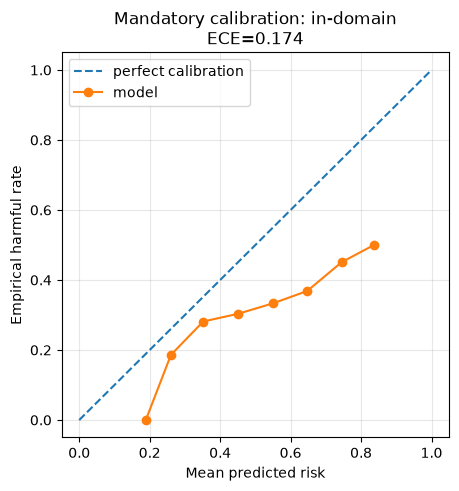

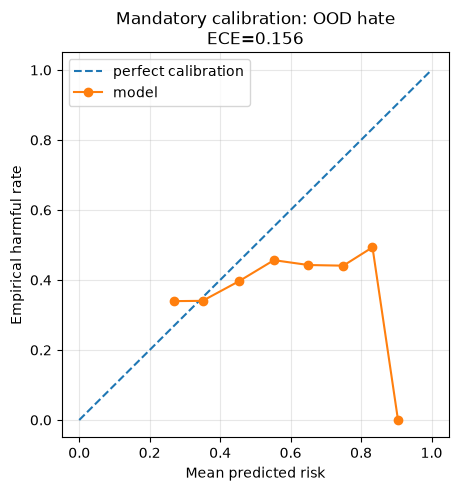

,split,ECE_10_bins,mean_pred,empirical_rate
0,eval,0.174384,0.491384,0.317
1,ood_hate,0.156422,0.572895,0.424


,threshold,flag_rate,precision,recall,false_positive_rate,mean_severity_flagged
0,0.20,0.9985,0.317476,1.000000,0.997804,0.170713
1,0.35,0.7745,0.342802,0.837539,0.745242,0.183313
2,0.50,0.4695,0.374867,0.555205,0.429722,0.198969
3,0.65,0.1855,0.439353,0.257098,0.152269,0.232768
4,0.80,0.0160,0.500000,0.025237,0.011713,0.267023


,threshold,flag_rate,precision,recall,false_positive_rate,mean_severity_flagged
0,0.20,1.0000,0.424000,1.000000,1.000000,0.219749
1,0.35,0.8895,0.436762,0.916274,0.869792,0.225226
2,0.50,0.6645,0.452220,0.708726,0.631944,0.231702
3,0.65,0.3515,0.455192,0.377358,0.332465,0.233343
4,0.80,0.0765,0.490196,0.088443,0.067708,0.251320


In [18]:
def calibration_table(y_true: np.ndarray, p_pred: np.ndarray, n_bins: int = 10) -> pd.DataFrame:
    y_true = np.asarray(y_true, dtype=float).reshape(-1)
    p_pred = np.asarray(p_pred, dtype=float).reshape(-1)
    bins = np.linspace(0.0, 1.0, n_bins + 1)
    rows = []
    for b in range(n_bins):
        lo, hi = bins[b], bins[b + 1]
        if b == n_bins - 1:
            mask = (p_pred >= lo) & (p_pred <= hi)
        else:
            mask = (p_pred >= lo) & (p_pred < hi)
        count = int(mask.sum())
        rows.append({
            "bin": b,
            "lo": float(lo),
            "hi": float(hi),
            "count": count,
            "fraction": float(count / max(len(y_true), 1)),
            "avg_pred": float(np.mean(p_pred[mask])) if count else np.nan,
            "empirical_rate": float(np.mean(y_true[mask])) if count else np.nan,
            "abs_gap": float(abs(np.mean(p_pred[mask]) - np.mean(y_true[mask]))) if count else np.nan,
        })
    return pd.DataFrame(rows)

def expected_calibration_error(y_true: np.ndarray, p_pred: np.ndarray, n_bins: int = 10) -> float:
    tab = calibration_table(y_true, p_pred, n_bins)
    return float(np.nansum(tab["fraction"].values * tab["abs_gap"].values))

def plot_reliability(y_true: np.ndarray, p_pred: np.ndarray, title: str, n_bins: int = 10):
    tab = calibration_table(y_true, p_pred, n_bins)
    plt.figure(figsize=(5, 5))
    plt.plot([0, 1], [0, 1], linestyle="--", label="perfect calibration")
    nonempty = tab[tab["count"] > 0]
    plt.plot(nonempty["avg_pred"], nonempty["empirical_rate"], marker="o", label="model")
    plt.xlabel("Mean predicted risk")
    plt.ylabel("Empirical harmful rate")
    plt.title(f"{title}\nECE={expected_calibration_error(y_true, p_pred, n_bins):.3f}")
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.show()
    return tab

eval_cal = plot_reliability(eval_df.label.values, risk_eval, "Mandatory calibration: in-domain")
ood_cal = plot_reliability(ood_df.label.values, risk_ood, "Mandatory calibration: OOD hate")

display(pd.DataFrame({
    "split": ["eval", "ood_hate"],
    "ECE_10_bins": [
        expected_calibration_error(eval_df.label.values, risk_eval, 10),
        expected_calibration_error(ood_df.label.values, risk_ood, 10),
    ],
    "mean_pred": [risk_eval.mean(), risk_ood.mean()],
    "empirical_rate": [eval_df.label.mean(), ood_df.label.mean()],
}))

def risk_threshold_analysis(df: pd.DataFrame, risk_probs: np.ndarray, thresholds: List[float]) -> pd.DataFrame:
    y = df["label"].values.astype(int)
    risk_probs = np.asarray(risk_probs, dtype=float)
    rows = []
    for thr in thresholds:
        flagged = risk_probs >= thr
        tp = np.sum(flagged & (y == 1))
        fp = np.sum(flagged & (y == 0))
        positives = max(np.sum(y == 1), 1)
        negatives = max(np.sum(y == 0), 1)
        rows.append({
            "threshold": float(thr),
            "flag_rate": float(np.mean(flagged)),
            "precision": float(tp / max(tp + fp, 1)),
            "recall": float(tp / positives),
            "false_positive_rate": float(fp / negatives),
            "mean_severity_flagged": float(df.loc[flagged, "severity"].mean()) if flagged.any() else np.nan,
        })
    return pd.DataFrame(rows)

thresholds = [0.2, 0.35, 0.5, 0.65, 0.8]
display(risk_threshold_analysis(eval_df, risk_eval, thresholds))
display(risk_threshold_analysis(ood_df, risk_ood, thresholds))


## 14. Final comparison and required written analysis

Now compare:

- unconstrained policies,
- safe policies,
- raw LinUCB,
- safe raw LinUCB,
- NeuralUCB-style LinUCB,
- safe NeuralUCB-style LinUCB,
- in-domain vs OOD behavior,
- calibration degradation.

### Task 14

Produce a final table and write a short explanation (here in the notebook) about it.

,policy,avg_reward_eval,avg_regret_eval,allow_rate_eval,review_rate_eval,block_rate_eval,harmful_allow_rate_eval,benign_block_rate_eval,avg_reward_ood,avg_regret_ood,...,block_rate_ood,harmful_allow_rate_ood,benign_block_rate_ood,delta_avg_reward_ood_minus_eval,delta_avg_regret_ood_minus_eval,delta_allow_rate_ood_minus_eval,delta_review_rate_ood_minus_eval,delta_block_rate_ood_minus_eval,delta_harmful_allow_rate_ood_minus_eval,delta_benign_block_rate_ood_minus_eval
0,oracle,1.008313,0.000000,0.6830,0.0000,0.317,0.000000,0.000000,1.009946,0.000000,...,0.424,0.000000,0.000000,0.001633,0.000000,-0.1070,0.0000,0.107,0.000000,0.000000
2,dropout_ts_mlp,0.408049,0.600265,0.8865,0.1135,0.000,0.839117,0.000000,0.224096,0.785850,...,0.000,0.741745,0.000000,-0.183953,0.185586,-0.1170,0.1170,0.000,-0.097371,0.000000
1,greedy_mlp,0.409210,0.599103,0.8965,0.1035,0.000,0.850158,0.000000,0.222128,0.787818,...,0.000,0.753538,0.000000,-0.187083,0.188716,-0.1175,0.1175,0.000,-0.096620,0.000000
3,ensemble_ts_mlp,0.398203,0.610110,0.9985,0.0015,0.000,1.000000,0.000000,0.193982,0.815964,...,0.000,0.990566,0.000000,-0.204222,0.205854,-0.0055,0.0055,0.000,-0.009434,0.000000
4,epsilon_0.10_mlp,0.358122,0.650191,0.8295,0.1305,0.040,0.783912,0.040264,0.185677,0.824270,...,0.040,0.708726,0.040799,-0.172446,0.174079,-0.1060,0.1060,0.000,-0.075185,0.000535


,policy,avg_reward_eval,avg_regret_eval,allow_rate_eval,review_rate_eval,block_rate_eval,harmful_allow_rate_eval,benign_block_rate_eval,avg_reward_ood,avg_regret_ood,...,block_rate_ood,harmful_allow_rate_ood,benign_block_rate_ood,delta_avg_reward_ood_minus_eval,delta_avg_regret_ood_minus_eval,delta_allow_rate_ood_minus_eval,delta_review_rate_ood_minus_eval,delta_block_rate_ood_minus_eval,delta_harmful_allow_rate_ood_minus_eval,delta_benign_block_rate_ood_minus_eval
0,safe_dropout_ts_mlp,0.388392,0.619921,0.6280,0.3560,0.0160,0.533123,0.011713,0.208985,0.800962,...,0.0765,0.389151,0.067708,-0.179407,0.181040,-0.1970,0.1365,0.0605,-0.143972,0.055995
2,safe_ensemble_ts_mlp,0.386957,0.621356,0.6310,0.3530,0.0160,0.539432,0.011713,0.208058,0.801888,...,0.0765,0.392689,0.067708,-0.178899,0.180532,-0.1975,0.1370,0.0605,-0.146743,0.055995
1,safe_greedy_mlp,0.387505,0.620809,0.6305,0.3535,0.0160,0.537855,0.011713,0.207708,0.802238,...,0.0765,0.392689,0.067708,-0.179796,0.181429,-0.1975,0.1370,0.0605,-0.145166,0.055995
3,safe_epsilon_0.10_mlp,0.346181,0.662132,0.5875,0.3540,0.0585,0.495268,0.049780,0.160064,0.849883,...,0.1165,0.373821,0.116319,-0.186118,0.187750,-0.1815,0.1235,0.0580,-0.121447,0.066539


,policy,cum_regret,avg_regret
3,safe_neuralucb_last_layer,1249.029275,0.624515
2,neuralucb_last_layer,1308.615167,0.654308
1,safe_linucb_raw,1463.455702,0.731728
0,linucb_raw,1506.243713,0.753122


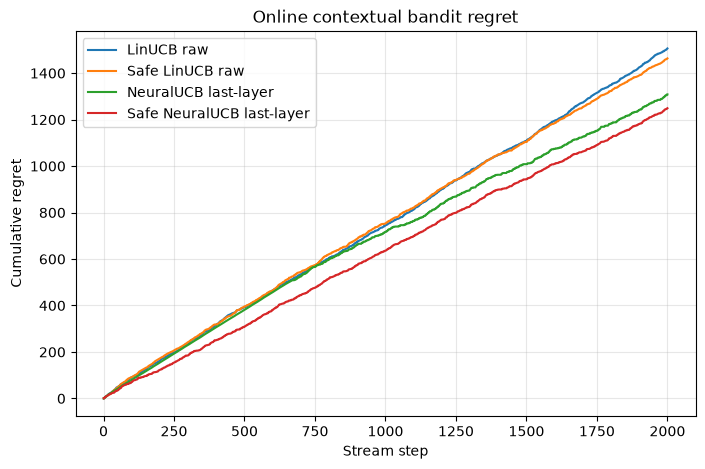

,split,family,policy,avg_reward,avg_regret,allow_rate,review_rate,block_rate,harmful_allow_rate,benign_block_rate
0,eval,unconstrained,oracle,1.008313,0.000000,0.6830,0.0000,0.3170,0.000000,0.000000
1,eval,unconstrained,greedy_mlp,0.409210,0.599103,0.8965,0.1035,0.0000,0.850158,0.000000
2,eval,unconstrained,dropout_ts_mlp,0.408049,0.600265,0.8865,0.1135,0.0000,0.839117,0.000000
3,eval,unconstrained,ensemble_ts_mlp,0.398203,0.610110,0.9985,0.0015,0.0000,1.000000,0.000000
10,eval,safe,safe_dropout_ts_mlp,0.388392,0.619921,0.6280,0.3560,0.0160,0.533123,0.011713
11,eval,safe,safe_greedy_mlp,0.387505,0.620809,0.6305,0.3535,0.0160,0.537855,0.011713
12,eval,safe,safe_ensemble_ts_mlp,0.386957,0.621356,0.6310,0.3530,0.0160,0.539432,0.011713
4,eval,unconstrained,epsilon_0.10_mlp,0.358122,0.650191,0.8295,0.1305,0.0400,0.783912,0.040264
13,eval,safe,safe_epsilon_0.10_mlp,0.346181,0.662132,0.5875,0.3540,0.0585,0.495268,0.049780
5,ood_hate,unconstrained,oracle,1.009946,0.000000,0.5760,0.0000,0.4240,0.000000,0.000000



Final analysis
--------------
1. The oracle row is the upper bound because it uses the simulator's full reward table for every context and action.
2. Among learned static policies, lower average regret is better. In this run, the best in-domain non-online policy is oracle with avg_regret=0.0000; on OOD hate data, the best row is oracle with avg_regret=0.0000.
3. Safe policies constrain actions using the risk model: high-risk examples cannot be allowed, and extreme-risk examples are blocked. This often reduces harmful_allow_rate but can increase benign_block_rate if the risk model is miscalibrated.
4. IPS and SNIPS use only logged propensities and can be high-variance when the target policy rarely matches the logging policy. The Direct Method can be biased if Q_hat is wrong. Doubly Robust combines both and is usually more stable.
5. OOD results and calibration plots are critical: a risk model trained on offensive tweets may be miscalibrated on hate tweets, so threshold-based safety rul

In [19]:

def policy_degradation_table(eval_results: pd.DataFrame, ood_results: pd.DataFrame) -> pd.DataFrame:
    """Compare in-domain and OOD performance for policies with the same names."""
    cols = [
        "policy", "avg_reward", "avg_regret", "allow_rate", "review_rate", "block_rate",
        "harmful_allow_rate", "benign_block_rate",
    ]
    e = eval_results[[c for c in cols if c in eval_results.columns]].copy()
    o = ood_results[[c for c in cols if c in ood_results.columns]].copy()
    merged = e.merge(o, on="policy", suffixes=("_eval", "_ood"), how="inner")

    for metric in ["avg_reward", "avg_regret", "allow_rate", "review_rate", "block_rate", "harmful_allow_rate", "benign_block_rate"]:
        if f"{metric}_eval" in merged.columns and f"{metric}_ood" in merged.columns:
            merged[f"delta_{metric}_ood_minus_eval"] = merged[f"{metric}_ood"] - merged[f"{metric}_eval"]

    return merged.sort_values("avg_regret_ood") if "avg_regret_ood" in merged.columns else merged

unconstrained_degradation = policy_degradation_table(eval_results, ood_results)
safe_degradation = policy_degradation_table(safe_eval_results, safe_ood_results)

display(unconstrained_degradation)
display(safe_degradation)

online_summary = pd.DataFrame([
    {
        "policy": "linucb_raw",
        "cum_regret": float(linucb_trace.cum_regret.iloc[-1]),
        "avg_regret": float(linucb_trace.regret.mean()),
    },
    {
        "policy": "safe_linucb_raw",
        "cum_regret": float(safe_linucb_trace.cum_regret.iloc[-1]),
        "avg_regret": float(safe_linucb_trace.regret.mean()),
    },
    {
        "policy": "neuralucb_last_layer",
        "cum_regret": float(neuralucb_trace.cum_regret.iloc[-1]),
        "avg_regret": float(neuralucb_trace.regret.mean()),
    },
    {
        "policy": "safe_neuralucb_last_layer",
        "cum_regret": float(safe_neuralucb_trace.cum_regret.iloc[-1]),
        "avg_regret": float(safe_neuralucb_trace.regret.mean()),
    },
])
display(online_summary.sort_values("avg_regret"))

# Final plots.
plt.figure(figsize=(8, 5))
plt.plot(linucb_trace["t"], linucb_trace["cum_regret"], label="LinUCB raw")
plt.plot(safe_linucb_trace["t"], safe_linucb_trace["cum_regret"], label="Safe LinUCB raw")
plt.plot(neuralucb_trace["t"], neuralucb_trace["cum_regret"], label="NeuralUCB last-layer")
plt.plot(safe_neuralucb_trace["t"], safe_neuralucb_trace["cum_regret"], label="Safe NeuralUCB last-layer")
plt.xlabel("Stream step")
plt.ylabel("Cumulative regret")
plt.title("Online contextual bandit regret")
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

final_static = pd.concat([
    eval_results.assign(split="eval", family="unconstrained"),
    ood_results.assign(split="ood_hate", family="unconstrained"),
    safe_eval_results.assign(split="eval", family="safe"),
    safe_ood_results.assign(split="ood_hate", family="safe"),
], ignore_index=True)

display(final_static[[
    "split", "family", "policy", "avg_reward", "avg_regret",
    "allow_rate", "review_rate", "block_rate", "harmful_allow_rate", "benign_block_rate",
]].sort_values(["split", "avg_regret"]))

best_eval = final_static[final_static["split"] == "eval"].sort_values("avg_regret").iloc[0]
best_ood = final_static[final_static["split"] == "ood_hate"].sort_values("avg_regret").iloc[0]

final_report = f"""
Final analysis
--------------
1. The oracle row is the upper bound because it uses the simulator's full reward table for every context and action.
2. Among learned static policies, lower average regret is better. In this run, the best in-domain non-online policy is {best_eval['policy']} with avg_regret={best_eval['avg_regret']:.4f}; on OOD hate data, the best row is {best_ood['policy']} with avg_regret={best_ood['avg_regret']:.4f}.
3. Safe policies constrain actions using the risk model: high-risk examples cannot be allowed, and extreme-risk examples are blocked. This often reduces harmful_allow_rate but can increase benign_block_rate if the risk model is miscalibrated.
4. IPS and SNIPS use only logged propensities and can be high-variance when the target policy rarely matches the logging policy. The Direct Method can be biased if Q_hat is wrong. Doubly Robust combines both and is usually more stable.
5. OOD results and calibration plots are critical: a risk model trained on offensive tweets may be miscalibrated on hate tweets, so threshold-based safety rules should be validated before deployment.
6. LinUCB explores online with uncertainty bonuses. NeuralUCB-style LinUCB uses learned representations, which can help if the reward model learned useful text features, but it can also inherit representation bias.
"""
print(final_report)


## Final written discussion

The experiment compares full-information oracle decisions, learned reward-model policies, uncertainty-based policies, safe variants, offline policy evaluation, and online UCB-style contextual bandits. The most important product lesson is that average reward alone is not enough for moderation. A policy can score well by allowing many posts, but the harmful-allow rate and the OOD calibration results determine whether it is safe enough to deploy.

The safe policies use a separate risk model to mask unsafe actions. This can reduce harmful allows, especially on high-risk contexts, but it may also block benign content when the risk model is overconfident or miscalibrated. The calibration and OOD sections therefore matter: threshold rules are only reliable when predicted probabilities correspond to actual harmful rates.

Offline policy evaluation illustrates the usual contextual-bandit tradeoff. IPS is unbiased under correct propensities but can have high variance; SNIPS reduces variance through normalization; the Direct Method is lower variance but model-biased; Doubly Robust combines the reward model and propensity correction. For deployment, the final decision should be based on reward, regret, harmful-allow rate, benign-block rate, and OOD calibration rather than a single scalar metric.


## Grading rubric

| Section | Points |
|---|---:|
| Real dataset loading, EDA, severity critique | 10 |
| Reward, oracle, regret | 10 |
| cost-sensitivity analysis | 10 |
| Logged bandit feedback and propensities | 10 |
| Reward model from chosen-action feedback | 15 |
| Fixed policies and uncertainty policies | 10 |
| safe exploration | 15 |
| Raw LinUCB | 10 |
| NeuralUCB-style LinUCB | 15 |
| Offline policy evaluation | 15 |
| calibration analysis | 15 |
| OOD stress analysis | 10 |
| Final safety/product discussion | 15 |


Total: 160 points.
